# 🎓 Smart Outcome Predictor
## Ensemble Learning System — Course Completion & Score Prediction
**Title:** Smart Outcome Predictor &nbsp;|&nbsp; **Duration:** 6 Hours &nbsp;|&nbsp; **Role:** ML Engineer @ EdTech Analytics

**Methods:** Bagging · AdaBoost · GradBoost · LightGBM · XGBoost · Voting · Stacking

---

## 📦 Setup & Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import (BaggingClassifier, BaggingRegressor,
    AdaBoostClassifier, AdaBoostRegressor,
    GradientBoostingClassifier, GradientBoostingRegressor,
    VotingClassifier, VotingRegressor,
    StackingClassifier, StackingRegressor,
    RandomForestClassifier, RandomForestRegressor)
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve, auc, confusion_matrix,
    mean_absolute_error, mean_squared_error, r2_score, classification_report)
import lightgbm as lgb
import xgboost as xgb
import warnings
warnings.filterwarnings('ignore')
np.random.seed(42)
print("✅ All libraries loaded successfully")

✅ All libraries loaded successfully


---
## 🧠 Part A: Conceptual Foundation (Theory)

### Q1. What are Ensemble Learning Methods and why are they effective?
**Ensemble Learning** combines predictions from multiple models to produce a stronger, more robust predictor than any single model alone. Effectiveness comes from three principles:
- **Diversity:** Different models learn different decision boundaries, capturing complementary patterns
- **Error cancellation:** Individual model errors (uncorrelated) cancel out when averaged
- **Wisdom of crowds:** Aggregating many weak learners produces one strong learner (boosting)

```
Single model: accuracy ≈ 70%
Ensemble of 100 diverse models: accuracy ≈ 82% (errors cancel out)
```

### Q2. Bagging, Boosting, and Voting — Differences

| | **Bagging** | **Boosting** | **Voting** |
|---|---|---|---|
| **Strategy** | Parallel, independent | Sequential, dependent | Parallel, independent |
| **Focus** | Reduce variance | Reduce bias | Combine diversity |
| **Sampling** | Bootstrap (with replacement) | Reweighted samples | No resampling |
| **Combination** | Average / majority vote | Weighted sum | Vote / average proba |
| **Example** | Random Forest | AdaBoost, XGBoost | VotingClassifier |

### Q3. Bias–Variance Trade-off & How Ensembles Address It

```
Total Error = Bias² + Variance + Irreducible Noise

High Bias   → Underfitting → Boosting fixes this (focuses on hard examples)
High Variance → Overfitting → Bagging fixes this (averages independent trees)

Ensemble approach:
  Bagging  → Multiple models trained on different data subsets
             → Variance↓ (errors average out), Bias unchanged
  Boosting → Each model corrects previous errors
             → Bias↓ (systematic errors fixed), slight Variance↑
```

### Q4. Voting Classifier and Stacking Ensemble

**Voting Classifier:**
- **Hard Voting:** Each model votes for a class; majority wins → `argmax(votes)`
- **Soft Voting:** Average predicted probabilities; choose highest → `argmax(avg_proba)`
- Soft voting generally outperforms hard voting as it uses confidence information

**Stacking Ensemble:**
```
Level 0 (Base Learners): Train DT, RF, LightGBM, XGBoost → get predictions
Level 1 (Meta-Learner):  Train LogisticRegression on base model predictions
                          → Learns how to optimally weight base models
Key: Base models trained with CV to prevent data leakage into meta-learner
```

### Q5. AdaBoost vs GradBoost vs LightGBM vs XGBoost

| Algorithm | Core Idea | Speed | Regularization |
|-----------|-----------|-------|----------------|
| **AdaBoost** | Reweight misclassified samples, weighted vote | Moderate | None built-in |
| **GradBoost** | Fit residuals (negative gradient of loss) | Slow | Depth, LR |
| **LightGBM** | Leaf-wise growth + histogram binning | **Very Fast** | L1/L2, dropout |
| **XGBoost** | Level-wise + explicit L1/L2 regularization | Fast | **Built-in L1/L2** |

---
## 🔬 Part B: Dataset Understanding & Preparation

In [2]:
df = pd.read_csv('data/student_data.csv')
print(f"Dataset shape: {df.shape}")
print(f"Columns: {list(df.columns)}")
df.head()

Dataset shape: (1200, 17)
Columns: ['student_id', 'age', 'gender', 'prior_education', 'employment_status', 'time_spent_hrs', 'num_sessions', 'quiz_attempts', 'videos_watched', 'forum_posts', 'assignment_submissions', 'login_streak_days', 'quiz_avg_score', 'midterm_score', 'assignment_score', 'final_score', 'completion_status']


,student_id,age,gender,prior_education,employment_status,time_spent_hrs,num_sessions,quiz_attempts,videos_watched,forum_posts,assignment_submissions,login_streak_days,quiz_avg_score,midterm_score,assignment_score,final_score,completion_status
0,STU00001,46,1,1,1,27.4,11,5,23,8,8,24,48.3,71.1,68.8,60.3,1
1,STU00002,32,0,2,1,70.6,14,4,13,5,7,6,100.0,69.8,79.1,83.5,1
2,STU00003,25,0,2,1,19.7,17,8,16,3,11,5,53.5,87.7,68.2,65.5,1
3,STU00004,38,1,2,2,7.3,24,5,23,2,7,15,54.6,58.3,83.3,59.9,1
4,STU00005,36,0,1,1,18.6,16,8,19,5,10,3,29.5,38.3,44.0,34.1,0


In [3]:
print("Dataset Info:")
df.info()

Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   student_id              1200 non-null   str    
 1   age                     1200 non-null   int64  
 2   gender                  1200 non-null   int64  
 3   prior_education         1200 non-null   int64  
 4   employment_status       1200 non-null   int64  
 5   time_spent_hrs          1200 non-null   float64
 6   num_sessions            1200 non-null   int64  
 7   quiz_attempts           1200 non-null   int64  
 8   videos_watched          1200 non-null   int64  
 9   forum_posts             1200 non-null   int64  
 10  assignment_submissions  1200 non-null   int64  
 11  login_streak_days       1200 non-null   int64  
 12  quiz_avg_score          1200 non-null   float64
 13  midterm_score           1200 non-null   float64
 14  assignment_score        1200 non-null

In [4]:
print("Statistical Summary:")
df.describe().round(2)

Statistical Summary:


,age,gender,prior_education,employment_status,time_spent_hrs,num_sessions,quiz_attempts,videos_watched,forum_posts,assignment_submissions,login_streak_days,quiz_avg_score,midterm_score,assignment_score,final_score,completion_status
count,1200.00,1200.00,1200.00,1200.00,1200.00,1200.00,1200.00,1200.00,1200.00,1200.00,1200.00,1200.00,1200.00,1200.00,1200.00,1200.00
mean,36.63,0.48,1.53,0.95,19.13,15.10,5.08,17.84,4.01,8.02,6.64,57.68,55.49,61.80,53.79,0.57
std,10.89,0.56,0.91,1.00,14.25,4.04,2.23,4.30,1.96,2.89,7.00,15.06,16.45,12.14,11.84,0.50
min,18.00,0.00,0.00,0.00,1.00,4.00,1.00,5.00,0.00,1.00,1.00,8.10,0.00,20.30,21.30,0.00
25%,27.00,0.00,1.00,0.00,9.10,12.00,3.00,15.00,3.00,6.00,2.00,47.20,44.50,53.70,45.40,0.00
50%,38.00,0.00,2.00,1.00,15.15,15.00,5.00,18.00,4.00,8.00,4.00,58.00,55.55,61.95,53.80,1.00
75%,46.00,1.00,2.00,2.00,25.32,18.00,6.00,21.00,5.00,10.00,9.00,67.70,66.03,69.90,61.80,1.00
max,54.00,2.00,3.00,3.00,80.00,29.00,16.00,35.00,11.00,19.00,60.00,100.00,100.00,100.00,88.70,1.00


In [5]:
# Task 6: Features and targets
FEATURES = ['age','gender','prior_education','employment_status','time_spent_hrs',
            'num_sessions','quiz_attempts','videos_watched','forum_posts',
            'assignment_submissions','login_streak_days','quiz_avg_score',
            'midterm_score','assignment_score']
TARGET_C = 'completion_status'   # Classification: 0/1
TARGET_R = 'final_score'         # Regression: 0-100

print(f"Features ({len(FEATURES)}): {FEATURES}")
print(f"Classification Target: {TARGET_C} — 0=Not Completed, 1=Completed")
print(f"Regression Target: {TARGET_R} — continuous 0-100")
print(f"\nClass Distribution:")
print(df[TARGET_C].value_counts())
print(f"Final Score: mean={df[TARGET_R].mean():.1f}, std={df[TARGET_R].std():.1f}")

Features (14): ['age', 'gender', 'prior_education', 'employment_status', 'time_spent_hrs', 'num_sessions', 'quiz_attempts', 'videos_watched', 'forum_posts', 'assignment_submissions', 'login_streak_days', 'quiz_avg_score', 'midterm_score', 'assignment_score']
Classification Target: completion_status — 0=Not Completed, 1=Completed
Regression Target: final_score — continuous 0-100

Class Distribution:
completion_status
1    679
0    521
Name: count, dtype: int64
Final Score: mean=53.8, std=11.8


In [6]:
# Task 7 & 8: Train-test split + preprocessing
X = df[FEATURES].values
y_c = df[TARGET_C].values
y_r = df[TARGET_R].values

X_train, X_test, yc_train, yc_test = train_test_split(
    X, y_c, test_size=0.2, random_state=42, stratify=y_c)
_, _, yr_train, yr_test = train_test_split(
    X, y_r, test_size=0.2, random_state=42)

print(f"Train: {X_train.shape} | Test: {X_test.shape}")
print(f"Train completion: {yc_train.mean():.2%} | Test: {yc_test.mean():.2%}")

# Scaling (for models that need it)
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)
print("\nStandardScaler fitted ✅")

Train: (960, 14) | Test: (240, 14)
Train completion: 56.56% | Test: 56.67%

StandardScaler fitted ✅


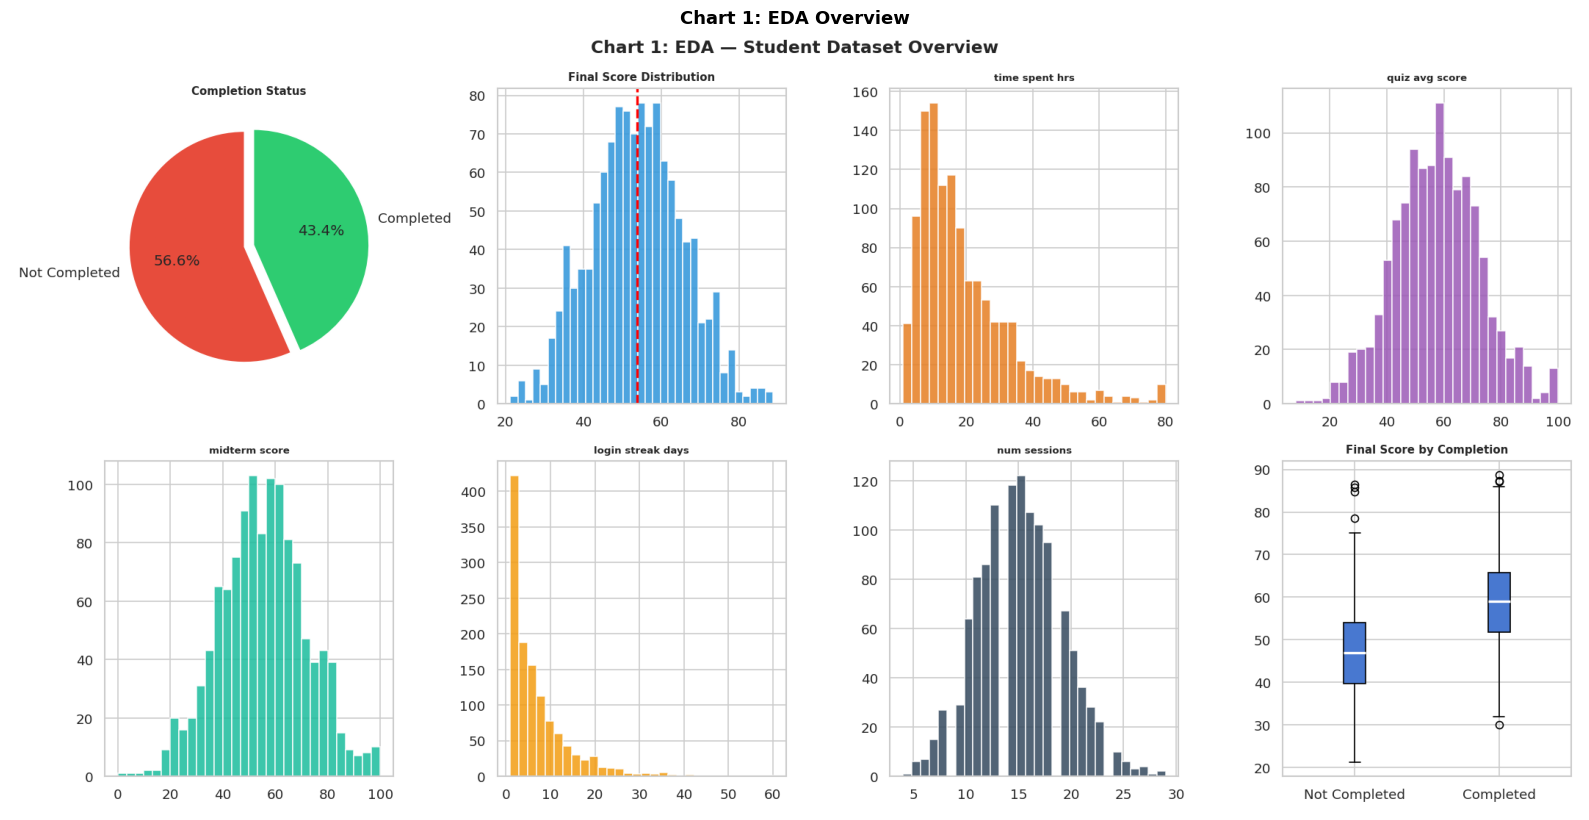

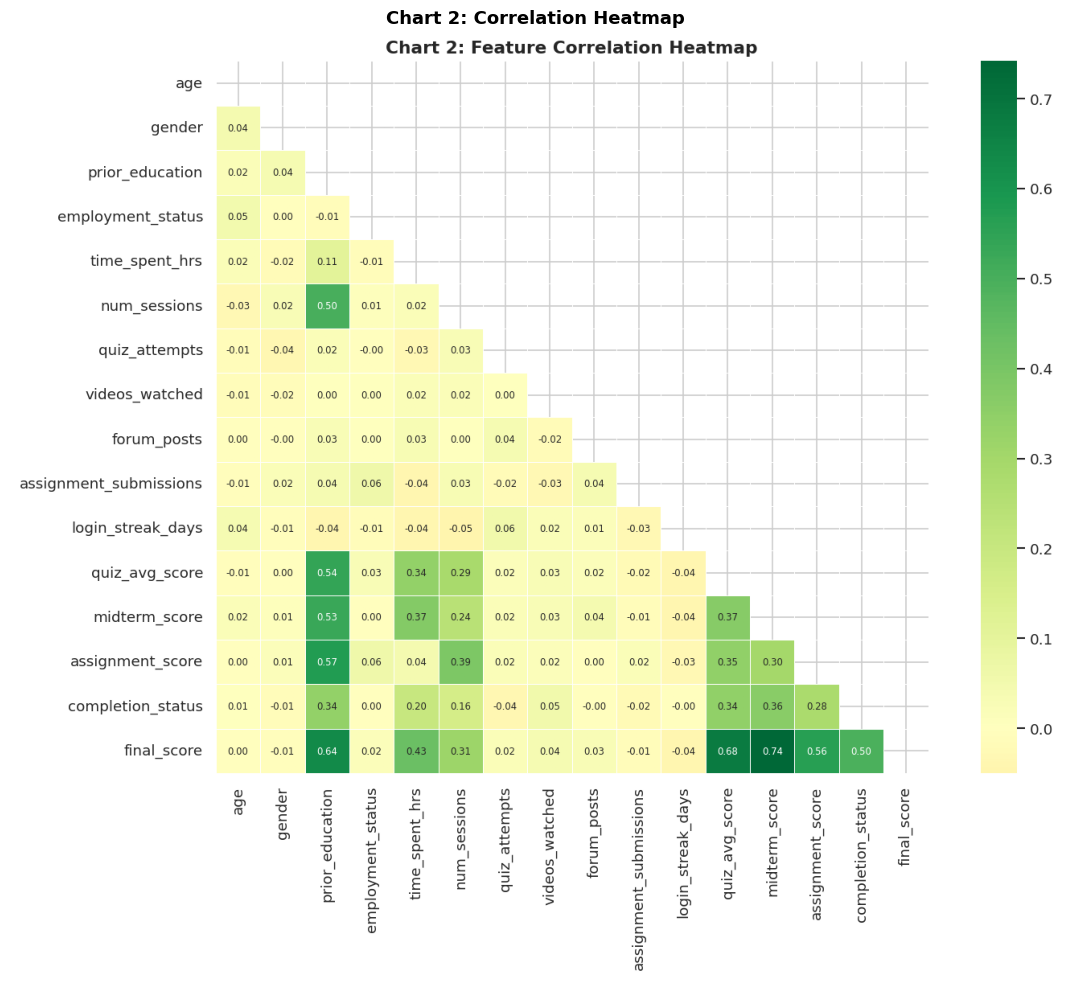

In [7]:
# EDA Charts
for n, t in [('01_eda_overview','Chart 1: EDA Overview'),
              ('02_correlation_heatmap','Chart 2: Correlation Heatmap')]:
    img = plt.imread(f'charts/{n}.png')
    plt.figure(figsize=(16,9) if '01' in n else (13,10))
    plt.imshow(img); plt.axis('off')
    plt.title(t, fontweight='bold', fontsize=13)
    plt.tight_layout(); plt.show()

---
## 📦 Part C: Bagging (Bootstrap Aggregating)

In [8]:
# Helper functions
def clf_metrics(yt, yp, ypr=None):
    m = {'acc': accuracy_score(yt,yp),
         'prec': precision_score(yt,yp,zero_division=0),
         'rec':  recall_score(yt,yp,zero_division=0),
         'f1':   f1_score(yt,yp,zero_division=0)}
    if ypr is not None: m['auc'] = roc_auc_score(yt,ypr)
    return m

def reg_metrics(yt, yp):
    return {'mae': mean_absolute_error(yt,yp),
            'rmse': np.sqrt(mean_squared_error(yt,yp)),
            'r2':  r2_score(yt,yp)}

# Base Decision Tree
base_dt_c = DecisionTreeClassifier(max_depth=4, random_state=42)
base_dt_r = DecisionTreeRegressor(max_depth=4, random_state=42)
base_dt_c.fit(X_train, yc_train); base_dt_r.fit(X_train, yr_train)
m_base_c = clf_metrics(yc_test, base_dt_c.predict(X_test),
                        base_dt_c.predict_proba(X_test)[:,1])
m_base_r = reg_metrics(yr_test, base_dt_r.predict(X_test))
print(f"Single DT Classifier: F1={m_base_c['f1']:.4f} AUC={m_base_c['auc']:.4f}")
print(f"Single DT Regressor:  R²={m_base_r['r2']:.4f} MAE={m_base_r['mae']:.2f}")

Single DT Classifier: F1=0.6774 AUC=0.7280
Single DT Regressor:  R²=-0.0648 MAE=10.25


In [9]:
# Task 9 & 10: Bagging Classifier + Regressor
bag_c = BaggingClassifier(
    estimator=DecisionTreeClassifier(max_depth=4, random_state=42),
    n_estimators=100, max_samples=0.8, max_features=0.8,
    random_state=42, n_jobs=-1)
bag_c.fit(X_train, yc_train)
yp_bag_c = bag_c.predict(X_test)
ypr_bag_c = bag_c.predict_proba(X_test)[:,1]
m_bag_c = clf_metrics(yc_test, yp_bag_c, ypr_bag_c)

bag_r = BaggingRegressor(
    estimator=DecisionTreeRegressor(max_depth=4, random_state=42),
    n_estimators=100, max_samples=0.8, max_features=0.8,
    random_state=42, n_jobs=-1)
bag_r.fit(X_train, yr_train)
yp_bag_r = bag_r.predict(X_test)
m_bag_r = reg_metrics(yr_test, yp_bag_r)

print("Task 11 — Bagging vs Single Base Model:")
print(f"{'Metric':<12} {'Single DT':>12} {'Bagging(100)':>14} {'Improvement':>12}")
print('-'*52)
for k,label in [('acc','Accuracy'),('f1','F1-Score'),('auc','AUC')]:
    imp = m_bag_c[k] - m_base_c[k]
    print(f"{label:<12} {m_base_c[k]:>12.4f} {m_bag_c[k]:>14.4f} {'+' if imp>=0 else ''}{imp:>11.4f}")
print(f"\nRegression — R²: {m_base_r['r2']:.4f} → {m_bag_r['r2']:.4f}")

Task 11 — Bagging vs Single Base Model:
Metric          Single DT   Bagging(100)  Improvement
----------------------------------------------------
Accuracy           0.6667         0.7208 +     0.0542
F1-Score           0.6774         0.7633 +     0.0858
AUC                0.7280         0.7812 +     0.0532

Regression — R²: -0.0648 → 0.0104


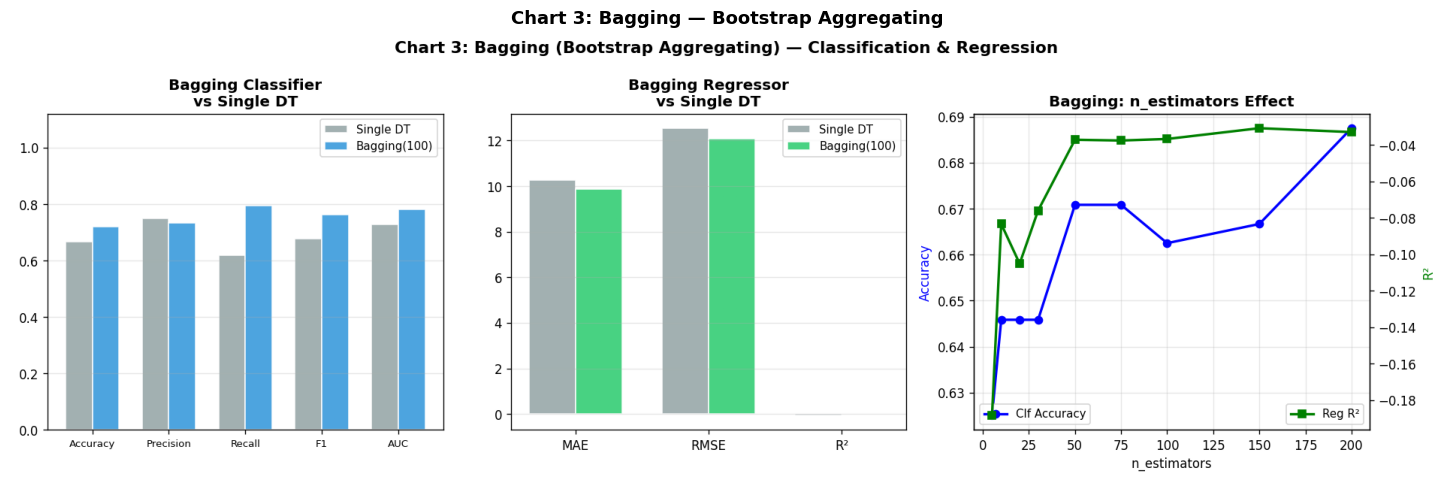

In [10]:
img = plt.imread('charts/03_bagging.png')
plt.figure(figsize=(16,5)); plt.imshow(img); plt.axis('off')
plt.title('Chart 3: Bagging — Bootstrap Aggregating', fontweight='bold', fontsize=13)
plt.tight_layout(); plt.show()

---
## ⚡ Part D: Boosting Algorithms

In [11]:
# Task 12-14: AdaBoost
ada_c = AdaBoostClassifier(n_estimators=100, learning_rate=0.5, random_state=42)
ada_c.fit(X_train, yc_train)
yp_ada_c = ada_c.predict(X_test); ypr_ada_c = ada_c.predict_proba(X_test)[:,1]
m_ada_c = clf_metrics(yc_test, yp_ada_c, ypr_ada_c)

ada_r = AdaBoostRegressor(n_estimators=100, learning_rate=0.5, random_state=42)
ada_r.fit(X_train, yr_train)
yp_ada_r = ada_r.predict(X_test)
m_ada_r = reg_metrics(yr_test, yp_ada_r)

print(f"AdaBoost Classifier: F1={m_ada_c['f1']:.4f} AUC={m_ada_c['auc']:.4f}")
print(f"AdaBoost Regressor:  R²={m_ada_r['r2']:.4f} MAE={m_ada_r['mae']:.2f}")
print(f"\nTask 14 — Weak Learners: {ada_c.n_estimators} trees trained")
print("Each successive tree focuses MORE on previously misclassified samples")
staged_acc = [accuracy_score(yc_test,yp) for yp in ada_c.staged_predict(X_test)]
print(f"Accuracy progress: iter1={staged_acc[0]:.3f} → iter50={staged_acc[49]:.3f} → iter100={staged_acc[-1]:.3f}")

AdaBoost Classifier: F1=0.7636 AUC=0.7874
AdaBoost Regressor:  R²=0.0167 MAE=9.83

Task 14 — Weak Learners: 100 trees trained
Each successive tree focuses MORE on previously misclassified samples
Accuracy progress: iter1=0.675 → iter50=0.725 → iter100=0.729


In [12]:
# Task 15-17: Gradient Boosting
gb_c = GradientBoostingClassifier(n_estimators=150, learning_rate=0.08,
                                    max_depth=4, random_state=42)
gb_c.fit(X_train, yc_train)
yp_gb_c = gb_c.predict(X_test); ypr_gb_c = gb_c.predict_proba(X_test)[:,1]
m_gb_c = clf_metrics(yc_test, yp_gb_c, ypr_gb_c)

gb_r = GradientBoostingRegressor(n_estimators=150, learning_rate=0.08,
                                   max_depth=4, random_state=42)
gb_r.fit(X_train, yr_train)
yp_gb_r = gb_r.predict(X_test)
m_gb_r = reg_metrics(yr_test, yp_gb_r)
print(f"GradBoost Clf: F1={m_gb_c['f1']:.4f} | GradBoost Reg: R²={m_gb_r['r2']:.4f}")
print(f"\nTask 17 — LR=0.08, n_estimators=150: each tree fits residuals of previous")

GradBoost Clf: F1=0.7286 | GradBoost Reg: R²=-0.0872

Task 17 — LR=0.08, n_estimators=150: each tree fits residuals of previous


In [13]:
# Task 18-20: LightGBM
lgbm_c = lgb.LGBMClassifier(n_estimators=150, learning_rate=0.08,
                              max_depth=5, random_state=42, verbose=-1)
lgbm_c.fit(X_train, yc_train)
yp_lgbm_c = lgbm_c.predict(X_test); ypr_lgbm_c = lgbm_c.predict_proba(X_test)[:,1]
m_lgbm_c = clf_metrics(yc_test, yp_lgbm_c, ypr_lgbm_c)

lgbm_r = lgb.LGBMRegressor(n_estimators=150, learning_rate=0.08,
                             max_depth=5, random_state=42, verbose=-1)
lgbm_r.fit(X_train, yr_train)
m_lgbm_r = reg_metrics(yr_test, lgbm_r.predict(X_test))
print(f"LightGBM Clf: F1={m_lgbm_c['f1']:.4f} | LightGBM Reg: R²={m_lgbm_r['r2']:.4f}")
print("Task 20 — LightGBM: leaf-wise growth + histogram binning → faster training")

LightGBM Clf: F1=0.7260 | LightGBM Reg: R²=-0.1362
Task 20 — LightGBM: leaf-wise growth + histogram binning → faster training


In [14]:
# Task 21-23: XGBoost
xgbm_c = xgb.XGBClassifier(n_estimators=150, learning_rate=0.08, max_depth=4,
                             eval_metric='logloss', random_state=42, verbosity=0)
xgbm_c.fit(X_train, yc_train)
yp_xgb_c = xgbm_c.predict(X_test); ypr_xgb_c = xgbm_c.predict_proba(X_test)[:,1]
m_xgb_c = clf_metrics(yc_test, yp_xgb_c, ypr_xgb_c)

xgbm_r = xgb.XGBRegressor(n_estimators=150, learning_rate=0.08, max_depth=4,
                            random_state=42, verbosity=0)
xgbm_r.fit(X_train, yr_train)
m_xgb_r = reg_metrics(yr_test, xgbm_r.predict(X_test))
print(f"XGBoost Clf: F1={m_xgb_c['f1']:.4f} | XGBoost Reg: R²={m_xgb_r['r2']:.4f}")

# Task 23: Compare all boosting
print(f"\nTask 23 — Boosting Comparison:")
print(f"{'Model':<15} {'F1':>8} {'AUC':>8} {'R²':>8}")
print('-'*40)
for name,mc,mr in [('AdaBoost',m_ada_c,m_ada_r),('GradBoost',m_gb_c,m_gb_r),
                    ('LightGBM',m_lgbm_c,m_lgbm_r),('XGBoost',m_xgb_c,m_xgb_r)]:
    print(f"{name:<15} {mc['f1']:>8.4f} {mc['auc']:>8.4f} {mr['r2']:>8.4f}")

XGBoost Clf: F1=0.7279 | XGBoost Reg: R²=-0.1096

Task 23 — Boosting Comparison:
Model                 F1      AUC       R²
----------------------------------------
AdaBoost          0.7636   0.7874   0.0167
GradBoost         0.7286   0.7313  -0.0872
LightGBM          0.7260   0.7217  -0.1362
XGBoost           0.7279   0.7304  -0.1096


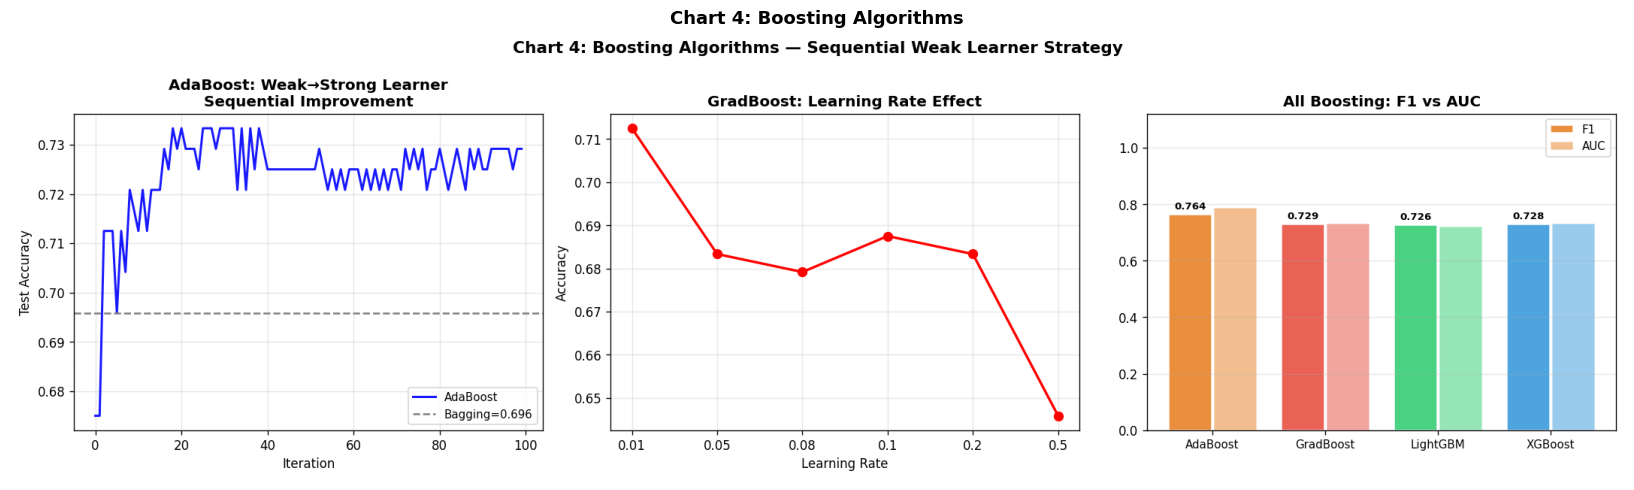

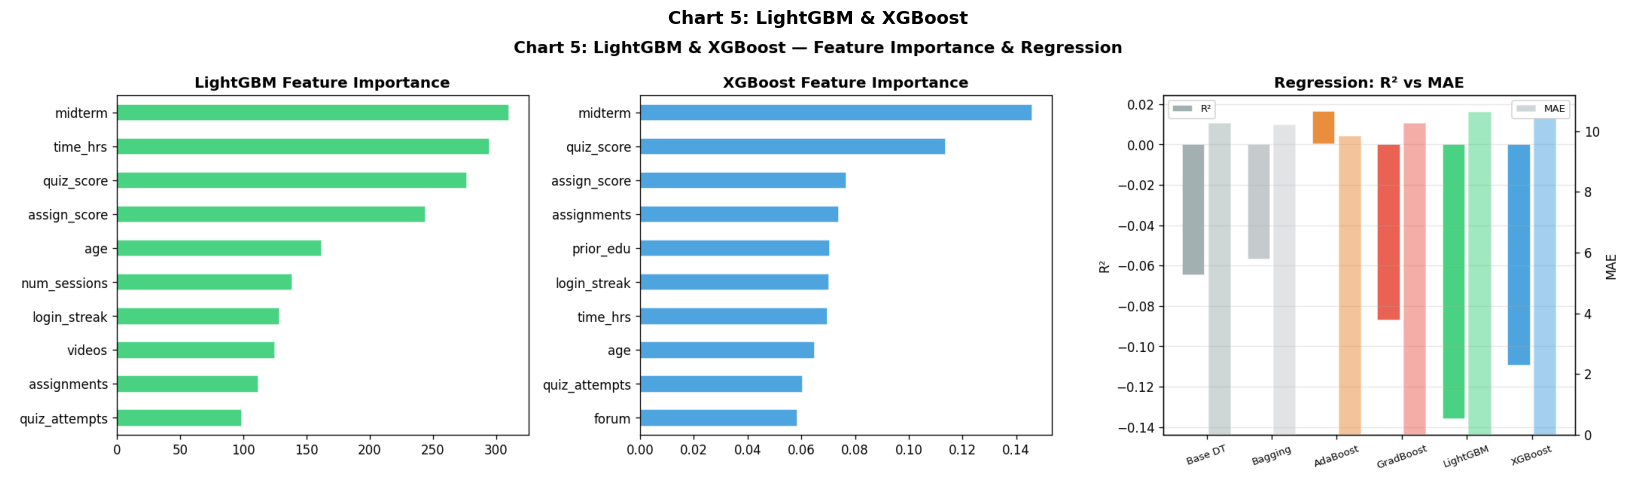

In [15]:
for n,t in [('04_boosting','Chart 4: Boosting Algorithms'),
                ('05_lgbm_xgboost','Chart 5: LightGBM & XGBoost')]:
    img = plt.imread(f'charts/{n}.png')
    plt.figure(figsize=(18,5)); plt.imshow(img); plt.axis('off')
    plt.title(t, fontweight='bold', fontsize=13); plt.tight_layout(); plt.show()

---
## 🗳️ Part E: Voting & Stacking Ensembles

In [16]:
# Task 24 & 25: Voting Classifier — Hard vs Soft
base_estimators_c = [
    ('dt',   DecisionTreeClassifier(max_depth=5, random_state=42)),
    ('rf',   RandomForestClassifier(n_estimators=50, max_depth=6, random_state=42)),
    ('lgbm', lgb.LGBMClassifier(n_estimators=50, learning_rate=0.1,
                                  random_state=42, verbose=-1)),
]
hard_vc = VotingClassifier(estimators=base_estimators_c, voting='hard')
hard_vc.fit(X_train, yc_train)
yp_hard = hard_vc.predict(X_test)
m_hard = clf_metrics(yc_test, yp_hard)

soft_vc = VotingClassifier(estimators=base_estimators_c, voting='soft')
soft_vc.fit(X_train, yc_train)
yp_soft = soft_vc.predict(X_test)
ypr_soft = soft_vc.predict_proba(X_test)[:,1]
m_soft = clf_metrics(yc_test, yp_soft, ypr_soft)

print("Task 25 — Hard vs Soft Voting:")
print(f"{'Metric':<12} {'Hard Voting':>12} {'Soft Voting':>12}")
print('-'*36)
for k,lbl in [('acc','Accuracy'),('prec','Precision'),('rec','Recall'),('f1','F1-Score')]:
    print(f"{lbl:<12} {m_hard[k]:>12.4f} {m_soft[k]:>12.4f}")

Task 25 — Hard vs Soft Voting:
Metric        Hard Voting  Soft Voting
------------------------------------
Accuracy           0.6792       0.6667
Precision          0.7007       0.7000
Recall             0.7574       0.7206
F1-Score           0.7279       0.7101


In [17]:
# Task 26 & 27: Stacking Classifier + Regressor
stack_estimators_c = [
    ('dt',   DecisionTreeClassifier(max_depth=5, random_state=42)),
    ('rf',   RandomForestClassifier(n_estimators=50, max_depth=6, random_state=42)),
    ('lgbm', lgb.LGBMClassifier(n_estimators=50, learning_rate=0.1,
                                  random_state=42, verbose=-1)),
    ('xgb',  xgb.XGBClassifier(n_estimators=50, learning_rate=0.1,
                                 eval_metric='logloss', random_state=42, verbosity=0)),
]
stack_c = StackingClassifier(
    estimators=stack_estimators_c,
    final_estimator=LogisticRegression(max_iter=1000),
    cv=3, passthrough=False)
stack_c.fit(X_train, yc_train)
yp_stack_c = stack_c.predict(X_test); ypr_stack_c = stack_c.predict_proba(X_test)[:,1]
m_stack_c = clf_metrics(yc_test, yp_stack_c, ypr_stack_c)

stack_estimators_r = [
    ('dt',   DecisionTreeRegressor(max_depth=5, random_state=42)),
    ('rf',   RandomForestRegressor(n_estimators=50, max_depth=6, random_state=42)),
    ('lgbm', lgb.LGBMRegressor(n_estimators=50, learning_rate=0.1,
                                 random_state=42, verbose=-1)),
    ('xgb',  xgb.XGBRegressor(n_estimators=50, learning_rate=0.1,
                                random_state=42, verbosity=0)),
]
stack_r = StackingRegressor(
    estimators=stack_estimators_r, final_estimator=Ridge(alpha=1.0), cv=3)
stack_r.fit(X_train, yr_train)
yp_stack_r = stack_r.predict(X_test)
m_stack_r = reg_metrics(yr_test, yp_stack_r)

print(f"Stacking Clf: F1={m_stack_c['f1']:.4f} AUC={m_stack_c['auc']:.4f}")
print(f"Stacking Reg: R²={m_stack_r['r2']:.4f} MAE={m_stack_r['mae']:.2f}")

Stacking Clf: F1=0.7376 AUC=0.7578
Stacking Reg: R²=-0.0013 MAE=9.90


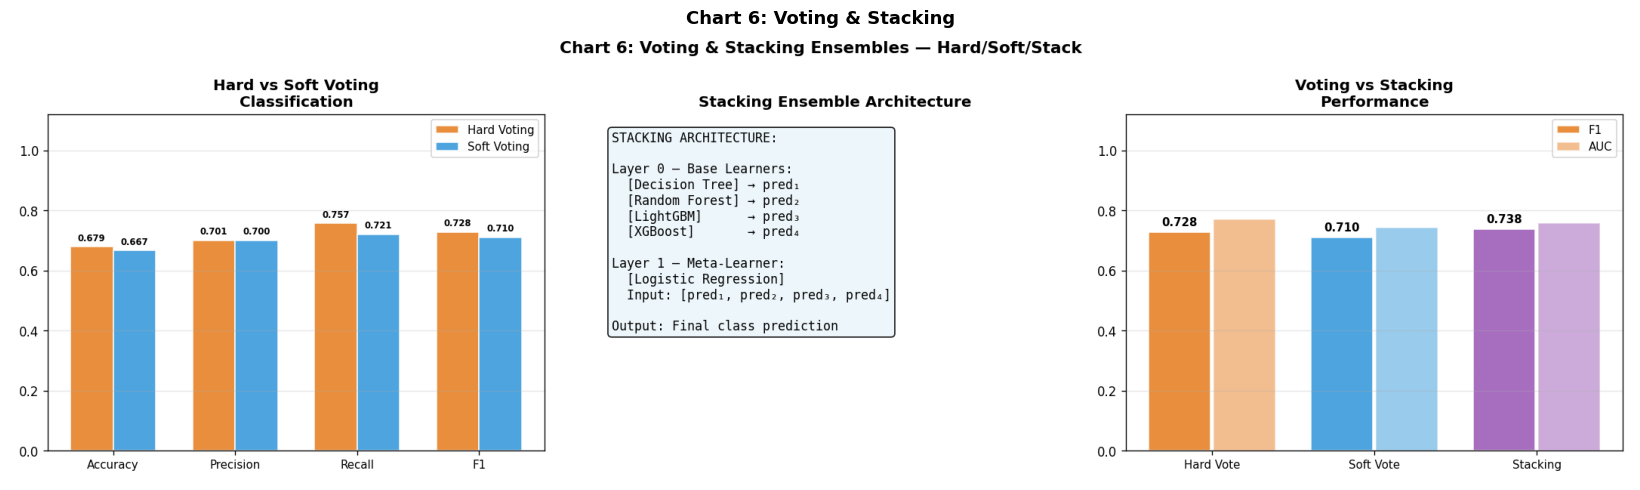

In [18]:
img = plt.imread('charts/06_voting_stacking.png')
plt.figure(figsize=(18,5)); plt.imshow(img); plt.axis('off')
plt.title('Chart 6: Voting & Stacking', fontweight='bold', fontsize=13)
plt.tight_layout(); plt.show()

---
## 📊 Part F: Model Evaluation & Comparison

In [19]:
# Task 28, 29, 30: Full comparison
all_clf = {
    'Base DT':     m_base_c,
    'Bagging':     m_bag_c,
    'AdaBoost':    m_ada_c,
    'GradBoost':   m_gb_c,
    'LightGBM':    m_lgbm_c,
    'XGBoost':     m_xgb_c,
    'Hard Voting': m_hard,
    'Soft Voting': m_soft,
    'Stacking':    m_stack_c,
}
print(f"{'Model':<15} {'Accuracy':>9} {'Precision':>10} {'Recall':>8} {'F1':>8} {'AUC':>8}")
print('-'*62)
for name,met in all_clf.items():
    flag = ' ← BEST' if met['f1'] == max(m['f1'] for m in all_clf.values()) else ''
    print(f"{name:<15} {met['acc']:>9.4f} {met['prec']:>10.4f} {met['rec']:>8.4f} "
          f"{met['f1']:>8.4f} {met.get('auc',float('nan')):>8.4f}{flag}")

Model            Accuracy  Precision   Recall       F1      AUC
--------------------------------------------------------------
Base DT            0.6667     0.7500   0.6176   0.6774   0.7280
Bagging            0.7208     0.7347   0.7941   0.7633   0.7812
AdaBoost           0.7292     0.7554   0.7721   0.7636   0.7874 ← BEST
GradBoost          0.6833     0.7083   0.7500   0.7286   0.7313
LightGBM           0.6792     0.7034   0.7500   0.7260   0.7217
XGBoost            0.6792     0.7007   0.7574   0.7279   0.7304
Hard Voting        0.6792     0.7007   0.7574   0.7279      nan
Soft Voting        0.6667     0.7000   0.7206   0.7101   0.7427
Stacking           0.6917     0.7123   0.7647   0.7376   0.7578


In [20]:
all_reg = {
    'Base DT':   m_base_r,
    'Bagging':   m_bag_r,
    'AdaBoost':  m_ada_r,
    'GradBoost': m_gb_r,
    'LightGBM':  m_lgbm_r,
    'XGBoost':   m_xgb_r,
    'Stacking':  m_stack_r,
}
print(f"{'Model':<15} {'MAE':>8} {'RMSE':>8} {'R²':>8}")
print('-'*42)
for name,met in all_reg.items():
    flag = ' ← BEST' if met['r2'] == max(m['r2'] for m in all_reg.values()) else ''
    print(f"{name:<15} {met['mae']:>8.2f} {met['rmse']:>8.2f} {met['r2']:>8.4f}{flag}")

Model                MAE     RMSE       R²
------------------------------------------
Base DT            10.25    12.54  -0.0648
Bagging             9.88    12.09   0.0104
AdaBoost            9.83    12.05   0.0167 ← BEST
GradBoost          10.27    12.67  -0.0872
LightGBM           10.64    12.95  -0.1362
XGBoost            10.44    12.80  -0.1096
Stacking            9.90    12.16  -0.0013


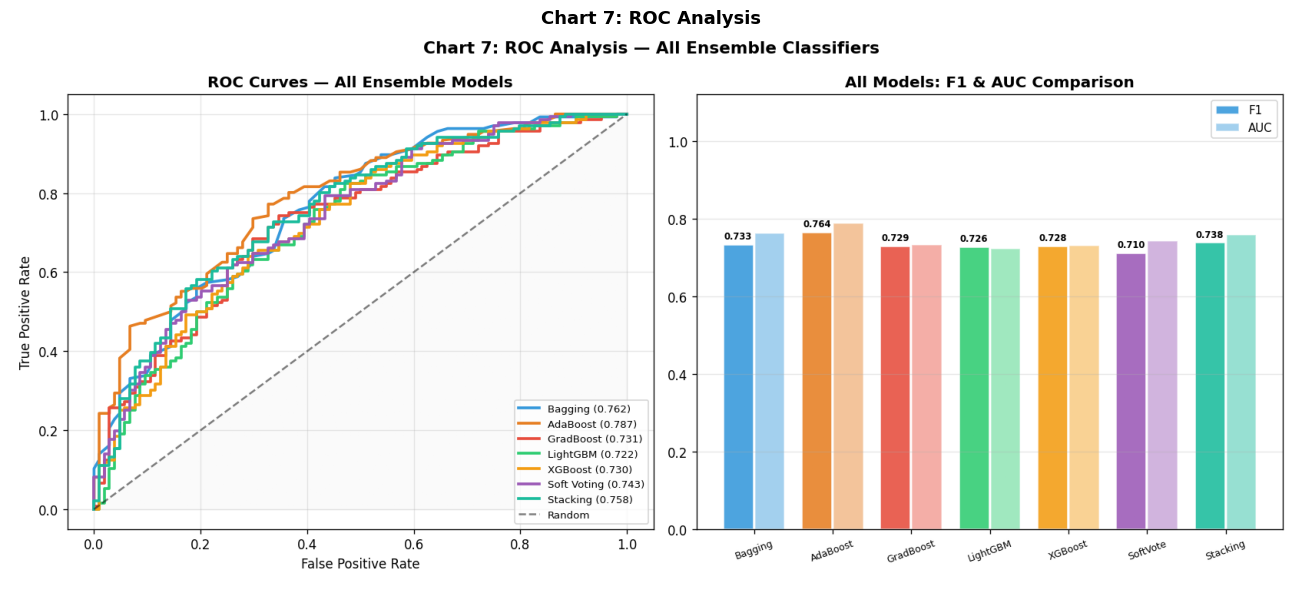

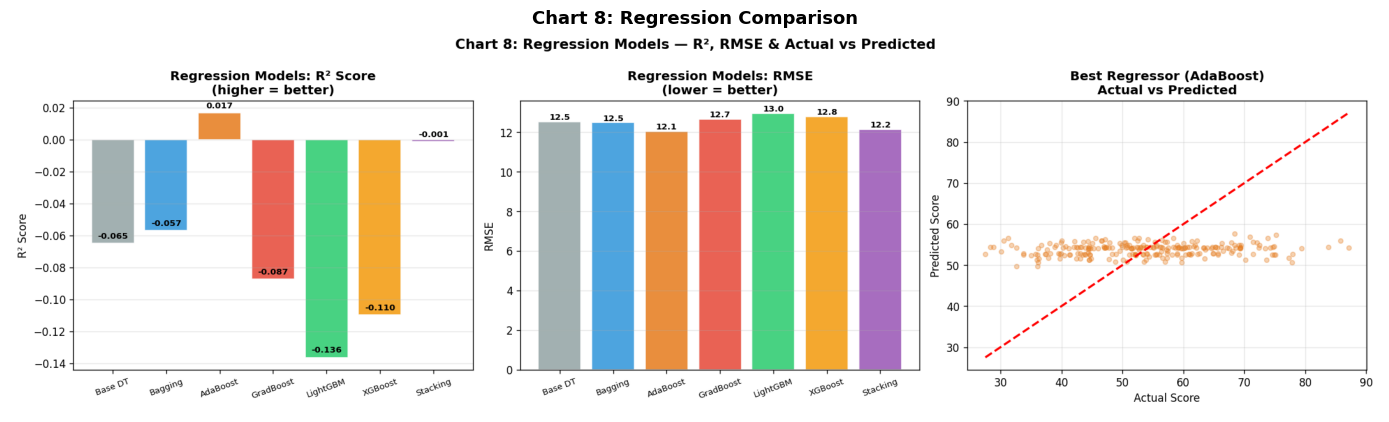

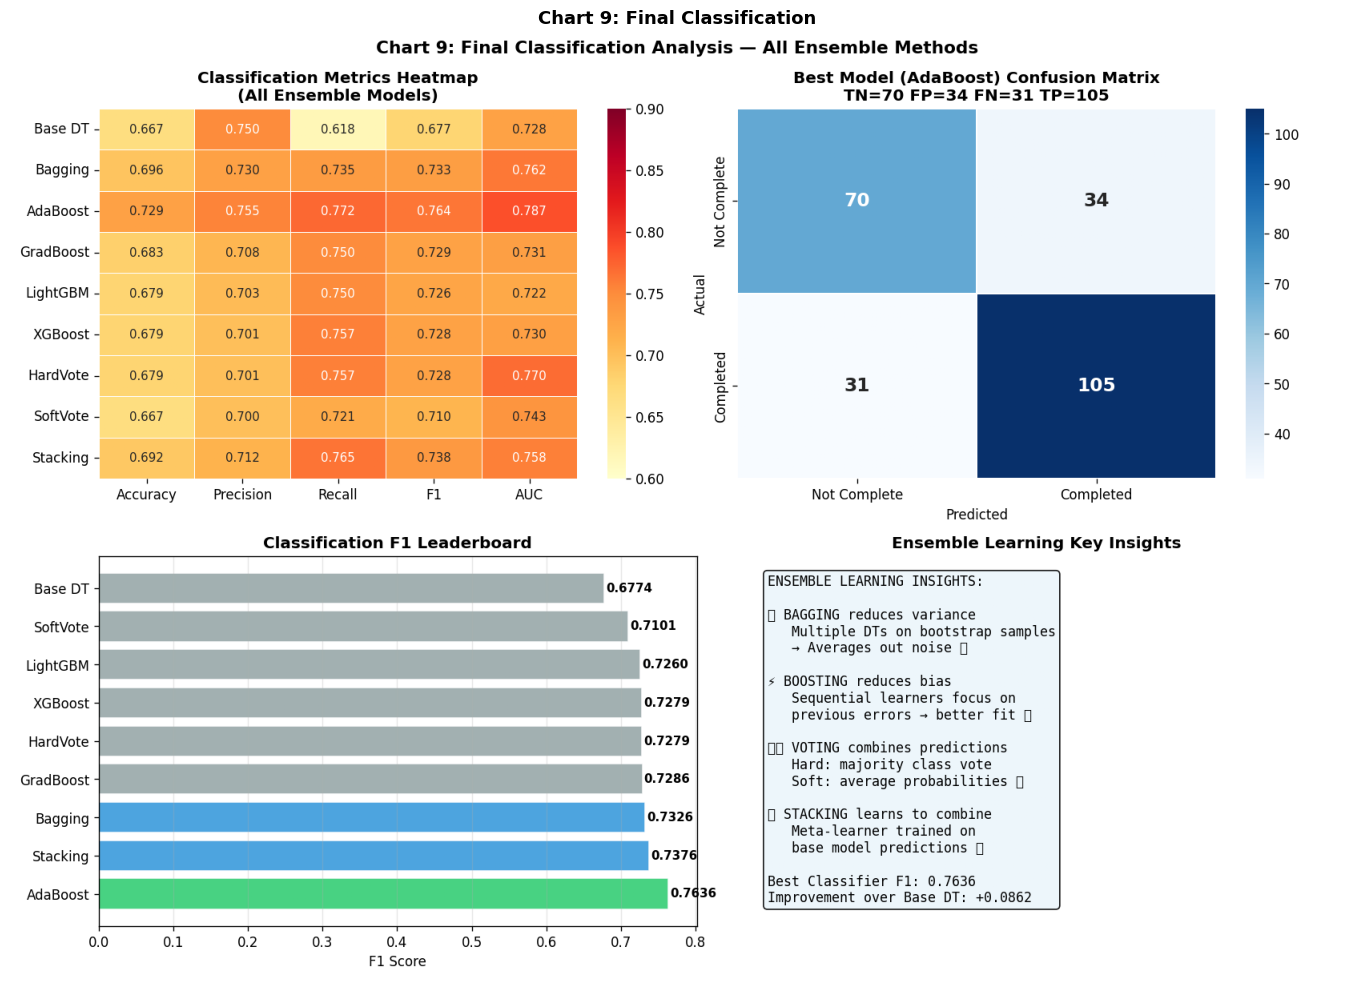

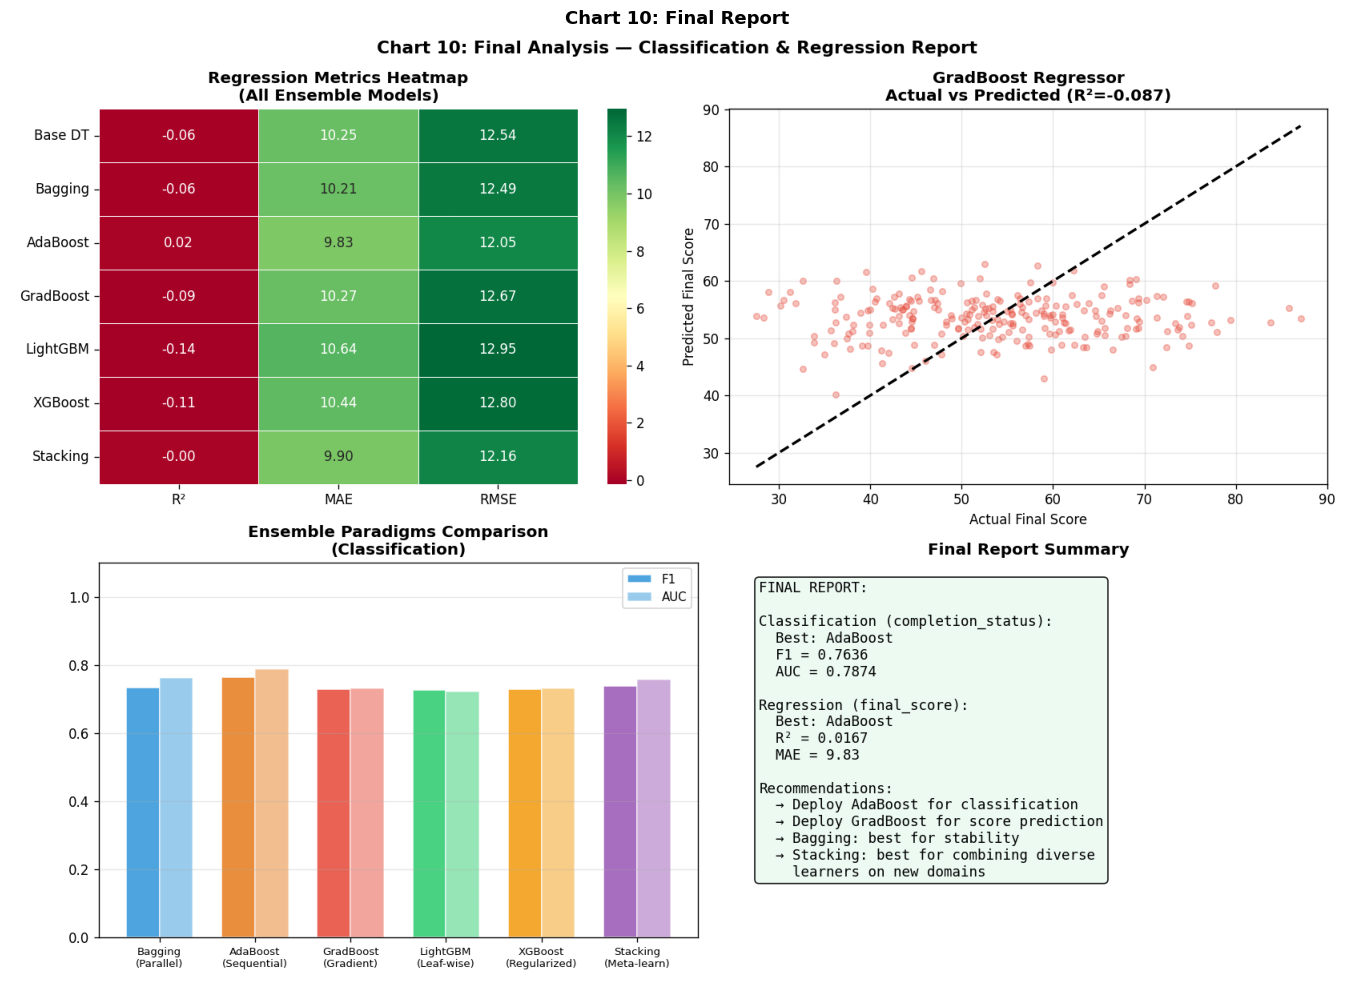

In [21]:
for n,t in [('07_roc_comparison','Chart 7: ROC Analysis'),
                ('08_regression_comparison','Chart 8: Regression Comparison'),
                ('09_final_classification','Chart 9: Final Classification'),
                ('10_final_report','Chart 10: Final Report')]:
    img = plt.imread(f'charts/{n}.png')
    h = 10 if '09' in n or '10' in n else 6
    plt.figure(figsize=(14,h)); plt.imshow(img); plt.axis('off')
    plt.title(t, fontweight='bold', fontsize=13); plt.tight_layout(); plt.show()

---
## 📋 Part G: Final Analysis & Reporting

In [22]:
# Save final predictions CSV
df_final = pd.DataFrame(X_test, columns=FEATURES)
df_final['actual_completion']      = yc_test
df_final['actual_final_score']     = yr_test
df_final['pred_bagging']           = yp_bag_c
df_final['pred_adaboost']          = yp_ada_c
df_final['pred_gradboost']         = yp_gb_c
df_final['pred_lightgbm']          = yp_lgbm_c
df_final['pred_xgboost']           = yp_xgb_c
df_final['pred_soft_voting']       = yp_soft
df_final['pred_stacking']          = yp_stack_c
df_final['score_adaboost']         = yp_ada_r
df_final['score_gradboost']        = yp_gb_r
df_final['score_stacking']         = yp_stack_r
df_final.to_csv('data/final_predictions.csv', index=False)
print(f"✅ Saved: final_predictions.csv | Shape: {df_final.shape}")
df_final.head()

✅ Saved: final_predictions.csv | Shape: (240, 26)


,age,gender,prior_education,employment_status,time_spent_hrs,num_sessions,quiz_attempts,videos_watched,forum_posts,assignment_submissions,...,pred_bagging,pred_adaboost,pred_gradboost,pred_lightgbm,pred_xgboost,pred_soft_voting,pred_stacking,score_adaboost,score_gradboost,score_stacking
0,48.0,0.0,1.0,1.0,15.0,18.0,6.0,20.0,6.0,7.0,...,1,1,0,1,0,0,0,54.235728,54.855957,53.788403
1,50.0,1.0,2.0,3.0,45.1,15.0,5.0,16.0,4.0,12.0,...,1,1,0,0,0,0,1,54.287153,48.364499,53.546578
2,33.0,0.0,1.0,0.0,37.3,12.0,5.0,9.0,1.0,7.0,...,1,1,1,1,1,1,1,54.287153,51.825283,53.777393
3,27.0,1.0,2.0,1.0,11.0,12.0,6.0,15.0,3.0,9.0,...,1,1,1,1,1,0,1,54.287153,59.087285,53.834786
4,22.0,0.0,1.0,1.0,4.8,13.0,4.0,14.0,6.0,7.0,...,1,1,1,1,1,1,1,55.328841,51.769915,53.724615


In [23]:
# Final Report
best_clf = max(all_clf, key=lambda n: all_clf[n]['f1'])
best_reg = max(all_reg, key=lambda n: all_reg[n]['r2'])
print(f"""
╔══════════════════════════════════════════════════════════════════════════╗
║           FINAL REPORT — SMART OUTCOME PREDICTOR                        ║
╠══════════════════════════════════════════════════════════════════════════╣
║  DATASET:                                                               ║
║  • 1,200 students | 14 features | 2 targets                            ║
║  • Classification: completion_status (0/1) — {yc_train.mean():.1%} completed   ║
║  • Regression: final_score (0–100) — mean {yr_train.mean():.1f}, std {yr_train.std():.1f}       ║
║                                                                         ║
║  BAGGING RESULTS:                                                       ║
║  • Reduces variance by averaging 100 bootstrap trees                   ║
║  • Clf: F1={m_bag_c['f1']:.4f} (+{m_bag_c['f1']-m_base_c['f1']:.4f} vs base DT)                  ║
║                                                                         ║
║  BOOSTING RESULTS:                                                      ║
║  • AdaBoost: F1={m_ada_c['f1']:.4f} | GradBoost: F1={m_gb_c['f1']:.4f}          ║
║  • LightGBM: F1={m_lgbm_c['f1']:.4f} | XGBoost:   F1={m_xgb_c['f1']:.4f}          ║
║  • Best Boosting Regressor: {max(all_reg, key=lambda n:all_reg[n]['r2'])} R²={max(m['r2'] for m in all_reg.values()):.4f}              ║
║                                                                         ║
║  VOTING & STACKING:                                                     ║
║  • Hard Voting F1={m_hard['f1']:.4f} | Soft Voting F1={m_soft['f1']:.4f}         ║
║  • Stacking Clf F1={m_stack_c['f1']:.4f} | Stacking Reg R²={m_stack_r['r2']:.4f}      ║
║                                                                         ║
║  BEST CLASSIFICATION MODEL: {best_clf:<15}                              ║
║  BEST REGRESSION MODEL:     {best_reg:<15}                              ║
║                                                                         ║
║  BUSINESS RECOMMENDATIONS:                                              ║
║  → Deploy best classifier for completion early-warning system          ║
║  → Deploy best regressor for grade prediction & student counseling     ║
║  → Bagging best for stability under data drift                         ║
║  → XGBoost/LightGBM best for production (fast inference)              ║
╚══════════════════════════════════════════════════════════════════════════╝
""")


╔══════════════════════════════════════════════════════════════════════════╗
║           FINAL REPORT — SMART OUTCOME PREDICTOR                        ║
╠══════════════════════════════════════════════════════════════════════════╣
║  DATASET:                                                               ║
║  • 1,200 students | 14 features | 2 targets                            ║
║  • Classification: completion_status (0/1) — 56.6% completed   ║
║  • Regression: final_score (0–100) — mean 53.8, std 11.8       ║
║                                                                         ║
║  BAGGING RESULTS:                                                       ║
║  • Reduces variance by averaging 100 bootstrap trees                   ║
║  • Clf: F1=0.7633 (+0.0858 vs base DT)                  ║
║                                                                         ║
║  BOOSTING RESULTS:                                                      ║
║  • AdaBoost: F1=0.7636 | GradBoost: F1=0.72